# Project 6 — Does optimization beat 1/N?
Six portfolio construction methods on the 11-ETF universe, monthly rebalancing,
rolling 60-month estimation window, out-of-sample May 2012 – September 2026, 10 bp
one-way costs. Question from DeMiguel, Garlappi and Uppal (2009), *Optimal Versus
Naive Diversification*, Review of Financial Studies 22(5).

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT.parent)]

import numpy as np
import pandas as pd

from common import data as D
from common.plotting import setup, source
from src import backtest as B

plt = setup()
DATA, FIG = ROOT / "data", ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = "{:.4f}".format

## Data
Daily adjusted closes (dividends reinvested) from yfinance, converted to month-end
total returns. HYG launched in April 2007, so May 2007 is the first full month for
all 11 ETFs. Risk-free rate: 3-month T-bill (FRED TB3MS), monthly.

In [2]:
px = D.prices(D.ETFS, "2007-04-01", "2026-10-01", DATA / "etf_prices_daily.csv")
R = D.monthly_returns(px).loc["2007-05":"2026-09"]
rf = D.tbill_monthly(DATA / "fred_TB3MS.csv")
assert R.notna().all().all() and len(R) == 233
R.to_csv(DATA / "etf_monthly_returns.csv")
print(R.index[0].date(), "to", R.index[-1].date(), len(R), "months")
R.describe().T[["mean", "std", "min", "max"]]

2007-05-31 to 2026-09-30 233 months


,mean,std,min,max
SPY,0.0096,0.0446,-0.1652,0.1270
EFA,0.0049,0.0501,-0.2083,0.1427
EEM,0.0058,0.0607,-0.2558,0.1686
IEF,0.0026,0.0194,-0.0473,0.0775
TLT,0.0029,0.0407,-0.1307,0.1434
TIP,0.0028,0.0167,-0.0809,0.0650
LQD,0.0033,0.0238,-0.1073,0.1381
HYG,0.0043,0.0294,-0.1145,0.1677
VNQ,0.0061,0.0641,-0.3173,0.3068
GLD,0.0088,0.0508,-0.1614,0.1279


## Base case: 60-month window, 10 bp

In [3]:
base = B.run(R, rf, window=60, cost_bps=10)
OOS = base["1/N"]["net"].index
print("Out-of-sample:", OOS[0].date(), "to", OOS[-1].date(), len(OOS), "months")


def table(res):
    return pd.DataFrame({k: B.stats(v["net"], rf, v["turnover"], v["weights"])
                         for k, v in res.items()}).T


T_base = table(base)
T_base["Sharpe (gross)"] = [B.sharpe(v["gross"] - rf.loc[OOS]) for v in base.values()]
T_base

Out-of-sample: 2012-05-31 to 2026-09-30 173 months


,Ann. return,Volatility,Sharpe,Sortino,Max drawdown,Calmar,Avg monthly turnover,Effective N,Sharpe (gross)
1/N,0.0517,0.0817,0.4499,0.6602,-0.1851,0.2792,0.0212,11.0000,0.4530
60/40,0.0916,0.0898,0.8338,1.3063,-0.2052,0.4466,0.0158,1.9231,0.8359
Min variance,0.0324,0.0504,0.3179,0.4385,-0.1342,0.2417,0.0447,3.9271,0.3283
Max Sharpe,0.0800,0.0794,0.8039,1.2769,-0.2029,0.3942,0.1386,3.0978,0.8260
Risk parity,0.0439,0.0679,0.4163,0.6073,-0.1739,0.2523,0.0262,8.7509,0.4209
Black-Litterman,0.0796,0.0904,0.7078,1.0912,-0.1568,0.5078,0.3297,4.2628,0.7515


## Is any Sharpe ratio different from 1/N? Stationary bootstrap, 5,000 draws

In [4]:
ex = {k: v["net"] - rf.loc[OOS] for k, v in base.items()}
boot = {k: B.bootstrap_sharpe_diff(ex[k], ex["1/N"], reps=5000)
        for k in B.STRATEGIES if k != "1/N"}
T_boot = pd.DataFrame(boot).T
T_boot

,diff,p_value,block_length,ci_low,ci_high
60/40,0.3839,0.0116,2.8441,0.1013,0.6829
Min variance,-0.1320,0.3304,1.8367,-0.3876,0.1464
Max Sharpe,0.3540,0.0344,1.6112,0.0268,0.6883
Risk parity,-0.0336,0.6412,1.8828,-0.1665,0.1093
Black-Litterman,0.2579,0.1056,2.5259,-0.0526,0.5682


## Robustness: 36-month window; 25 bp costs

In [5]:
rob36 = B.run(R, rf, window=36, cost_bps=10, start=OOS[0])
rob25 = {k: {**v, "net": v["gross"] - v["turnover"] * 25 / 1e4} for k, v in base.items()}
T36, T25 = table(rob36), table(rob25)
boot36 = {k: B.bootstrap_sharpe_diff(rob36[k]["net"] - rf.loc[OOS],
                                     rob36["1/N"]["net"] - rf.loc[OOS])["p_value"]
          for k in B.STRATEGIES if k != "1/N"}
boot25 = {k: B.bootstrap_sharpe_diff(rob25[k]["net"] - rf.loc[OOS],
                                     rob25["1/N"]["net"] - rf.loc[OOS])["p_value"]
          for k in B.STRATEGIES if k != "1/N"}
pd.DataFrame({"Sharpe 60m/10bp": T_base["Sharpe"], "Sharpe 36m/10bp": T36["Sharpe"],
              "Sharpe 60m/25bp": T25["Sharpe"],
              "p 36m": pd.Series(boot36), "p 25bp": pd.Series(boot25)})

,Sharpe 60m/10bp,Sharpe 36m/10bp,Sharpe 60m/25bp,p 36m,p 25bp
1/N,0.4499,0.4499,0.4453,NaN,NaN
60/40,0.8338,0.8338,0.8307,0.0116,0.0110
Black-Litterman,0.7078,0.7190,0.6422,0.0940,0.2156
Max Sharpe,0.8039,0.7663,0.7709,0.1016,0.0544
Min variance,0.3179,0.3173,0.3022,0.2890,0.2892
Risk parity,0.4163,0.4120,0.4094,0.6346,0.6154


## Subperiods: is the result driven by one stretch?
Sharpe ratios and bootstrap p-values vs. 1/N before and after 2024, when gold rallied
and the 40%-capped optimizers held large gold positions.

In [6]:
sub = {}
for lab, (a, b) in {"May 2012 - Dec 2023": ("2012-05", "2023-12"),
                    "Jan 2024 - Sep 2026": ("2024-01", "2026-09")}.items():
    sub[lab + " Sharpe"] = {k: B.sharpe(e.loc[a:b]) for k, e in ex.items()}
    sub[lab + " p vs 1/N"] = {k: B.bootstrap_sharpe_diff(ex[k].loc[a:b], ex["1/N"].loc[a:b])["p_value"]
                              for k in B.STRATEGIES if k != "1/N"}
T_sub = pd.DataFrame(sub)
T_sub

,May 2012 - Dec 2023 Sharpe,May 2012 - Dec 2023 p vs 1/N,Jan 2024 - Sep 2026 Sharpe,Jan 2024 - Sep 2026 p vs 1/N
1/N,0.3680,NaN,0.8811,NaN
60/40,0.8089,0.0068,0.9506,0.8784
Min variance,0.3264,0.7660,0.2745,0.1004
Max Sharpe,0.5517,0.2288,1.6158,0.1650
Risk parity,0.3185,0.5090,0.8880,0.9618
Black-Litterman,0.5482,0.3004,1.2818,0.2278


## Charts

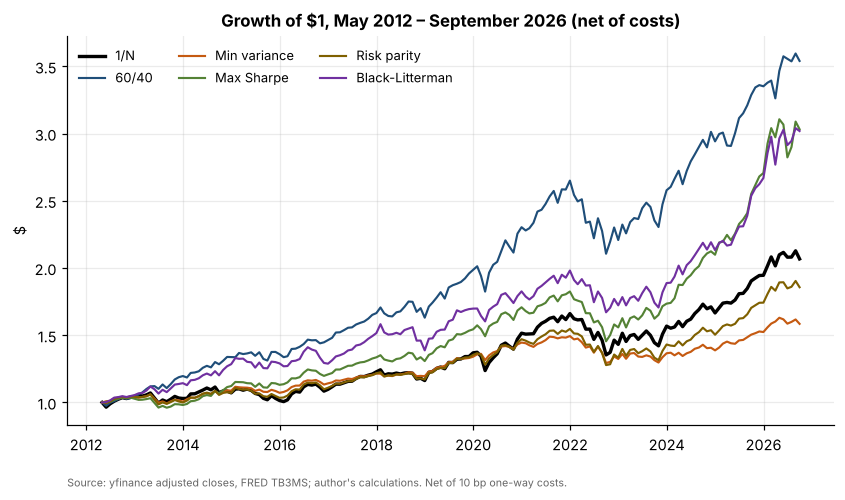

In [7]:
SRC = "Source: yfinance adjusted closes, FRED TB3MS; author's calculations. Net of 10 bp one-way costs."
fig, ax = plt.subplots(figsize=(9, 4.6))
for k, v in base.items():
    w = (1 + v["net"]).cumprod()
    w = pd.concat([pd.Series([1.0], [OOS[0] - pd.offsets.MonthEnd(1)]), w])
    ax.plot(w.index, w, lw=2.2 if k == "1/N" else 1.4, label=k,
            color="black" if k == "1/N" else None)
ax.set_title("Growth of $1, May 2012 – September 2026 (net of costs)")
ax.set_ylabel("$"); ax.legend(ncol=3, fontsize=8.5)
source(ax, SRC)
fig.savefig(FIG / "fig1_cumulative.png"); plt.show()

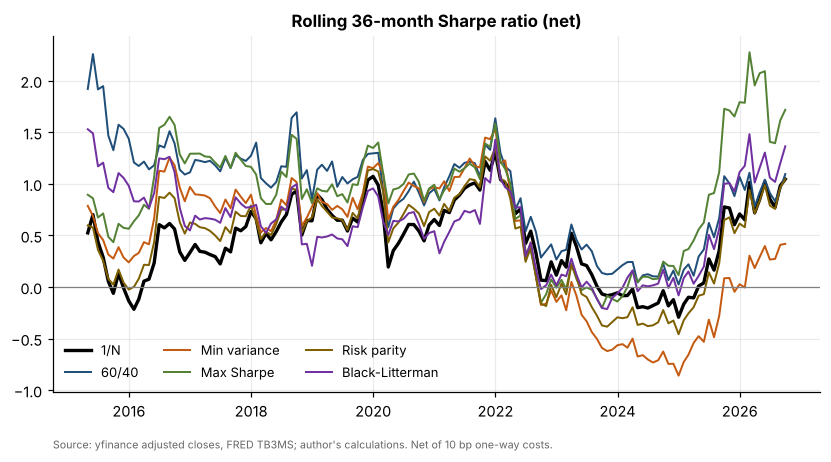

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for k, e in ex.items():
    rs = e.rolling(36).mean() / e.rolling(36).std() * np.sqrt(12)
    ax.plot(rs.index, rs, lw=2.2 if k == "1/N" else 1.3, label=k,
            color="black" if k == "1/N" else None)
ax.axhline(0, color="grey", lw=0.8)
ax.set_title("Rolling 36-month Sharpe ratio (net)")
ax.legend(ncol=3, fontsize=8.5)
source(ax, SRC)
fig.savefig(FIG / "fig2_rolling_sharpe.png"); plt.show()

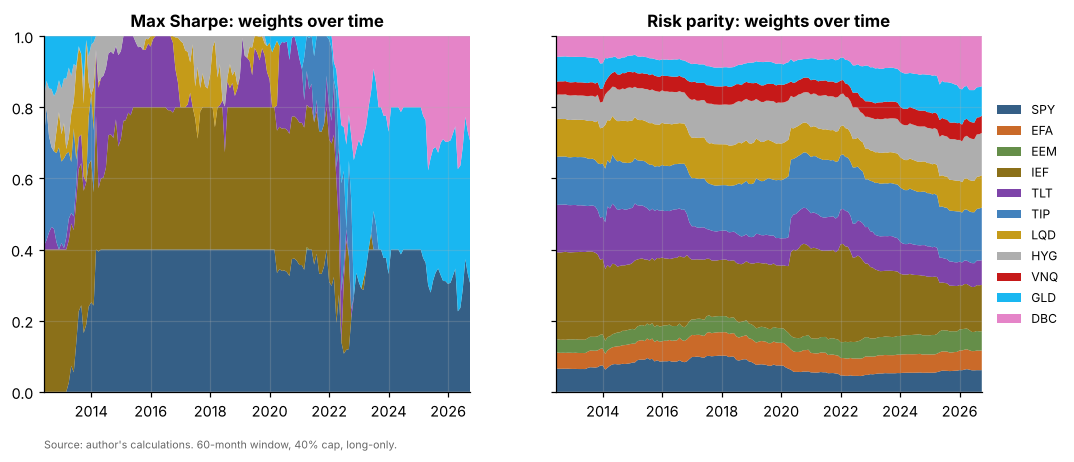

In [9]:
from common.plotting import PALETTE
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, k in zip(axes, ["Max Sharpe", "Risk parity"]):
    W = base[k]["weights"]
    ax.stackplot(W.index, W.T.values, labels=W.columns, colors=PALETTE, alpha=0.9)
    ax.set_title(f"{k}: weights over time"); ax.set_ylim(0, 1); ax.margins(x=0)
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
source(axes[0], "Source: author's calculations. 60-month window, 40% cap, long-only.")
fig.savefig(FIG / "fig3_weights.png"); plt.show()

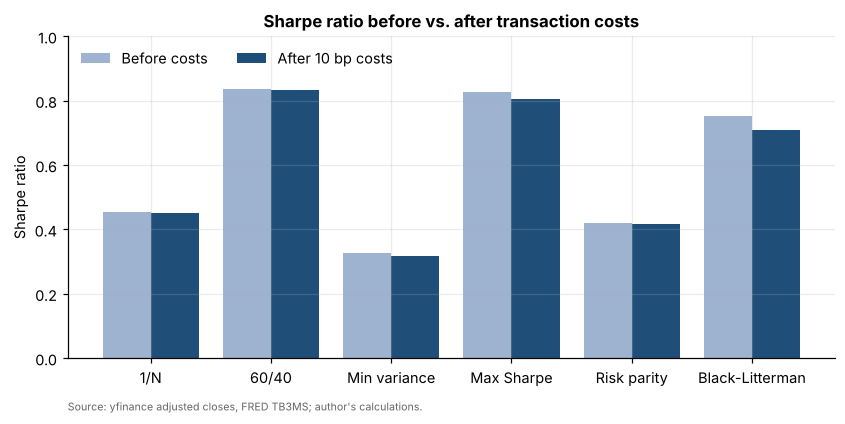

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(B.STRATEGIES))
ax.bar(x - 0.2, T_base["Sharpe (gross)"], 0.4, label="Before costs", color="#9DB3CF")
ax.bar(x + 0.2, T_base["Sharpe"], 0.4, label="After 10 bp costs", color="#1F4E79")
ax.set_xticks(x, B.STRATEGIES); ax.set_ylabel("Sharpe ratio"); ax.set_ylim(0, 1.0)
ax.legend(loc="upper left", ncol=2)
ax.set_title("Sharpe ratio before vs. after transaction costs")
source(ax, SRC.replace(" Net of 10 bp one-way costs.", ""))
fig.savefig(FIG / "fig4_sharpe_costs.png"); plt.show()

## Save results for the report and README

In [11]:
T_base.to_csv(DATA / "results_base.csv")
T_boot.to_csv(DATA / "bootstrap_vs_1n.csv")
T36.to_csv(DATA / "results_window36.csv")
T25.to_csv(DATA / "results_cost25.csv")
T_sub.to_csv(DATA / "subperiods.csv")
pd.DataFrame({k: v["net"] for k, v in base.items()}).to_csv(DATA / "net_returns_base.csv")
for k in ["Max Sharpe", "Risk parity", "Black-Litterman", "Min variance"]:
    base[k]["weights"].to_csv(DATA / f"weights_{k.lower().replace(' ', '_').replace('/', '')}.csv")
json.dump({"oos_start": str(OOS[0].date()), "oos_end": str(OOS[-1].date()),
           "n_months": len(OOS), "p_window36": boot36, "p_cost25": boot25},
          open(DATA / "meta.json", "w"), indent=2)